# Sales Analytics & Prediction

**Project:** End-to-end data science -- data generation, exploration, business KPI,
prediction, and forecasting -- applied to a realistic sales dataset.

This is a **publishable** repository: the analysis script, a documented notebook,
visualizations, a trained model, and a forecast are all packaged together with a
README ready for sharing.


## Dataset

The project ships with a **synthetic sales dataset** (~6,000 line items) spanning
January 2023 -- December 2024. It is fully self-contained (no external downloads or
API keys required) and mirrors a real retail/transaction log:

| Field | Meaning |
| --- | --- |
| `date` | Transaction timestamp |
| `country` `region` | Geography |
| `category` `sub_category` `channel` `segment` | Product / channel / customer |
| `units_sold` | Quantity |
| `unit_price` `cost_price` | Pricing & cost |
| `discount_percent` | Promotional discount |
| `shipping_cost` | Fulfillment cost |

Key business questions we answer:

* How is revenue distributed across regions, categories, and channels?
* What is the seasonal pattern of sales?
* How strongly do discounts and product mix drive profit?
* Can we **predict per-item sales (units sold)** from product/channel/segment features?
* Can we **forecast monthly revenue** for the horizon after the data?

## 1. Data generation & loading

We generate a deterministic (seeded) synthetic dataset, then run standard cleaning
(correct datetime parsing, drop rows missing core fields, remove duplicates, drop
impossible values). Re-running the same seed produces exactly the same data, so the
whole analysis is reproducible.

In [1]:
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from data import generate_sales_data, clean_data

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

raw = generate_sales_data(n=6000, seed=42)
clean = clean_data(raw)
print("Generated", len(raw), "line items")
print("After cleaning:", len(clean), "rows")
print("Nulls / duplicates:", int(clean.isna().sum().sum()), "/",
      int(clean.duplicated().sum()))
print("Columns:", list(clean.columns))

Generated 6000 line items
After cleaning: 5985 rows
Nulls / duplicates: 0 / 0
Columns: ['date', 'country', 'category', 'region', 'sub_category', 'channel', 'segment', 'month', 'year', 'weekday', 'units_sold', 'unit_price', 'discount_percent', 'shipping_cost', 'cost_price', 'line_total', 'gross_profit', 'discount_amount']


## 2. Data quality & cleaning

Every column is numeric-safe; there are **no missing values and no duplicate rows**
in the cleaned frame. The cleaning pipeline (in `src/data.py`) guarantees:
- correct `datetime` parsing,
- positive `units_sold` and `unit_price`,
- non-negative costs and discounts (clipped to <= 1.0), 
- derived metrics (`line_total`, `gross_profit`, `discount_amount`).

In [2]:
print('Shape:', clean.shape)
print('Total rows:', len(clean))
print('Missing values:', clean.isna().sum().sum())
print('Duplicate rows:', int(clean.duplicated().sum()))
print('\nDtypes:\n', clean.dtypes.value_counts())
print('\nSummary statistics:\n', clean.describe().round(2).T[['mean','std','min','25%','50%','75%','max']])

Shape: (5985, 18)
Total rows: 5985
Missing values: 0
Duplicate rows: 0

Dtypes:
 float64           7
str               6
int32             3
datetime64[us]    1
int64             1
Name: count, dtype: int64

Summary statistics:
                                         mean      std                  min  \
date              2023-12-28 02:03:54.586466      NaN  2023-01-01 00:00:00   
month                                   6.48     3.44                  1.0   
year                                 2023.49      0.5               2023.0   
weekday                                  2.3     1.67                  0.0   
units_sold                             33.38    21.38                  5.0   
unit_price                             67.25    43.34                 0.61   
discount_percent                        0.16     0.17                 0.02   
shipping_cost                           6.06     4.32                 0.07   
cost_price                             39.42    26.21                

## 3. Exploratory analysis

The charts below answer the distribution and trend questions.

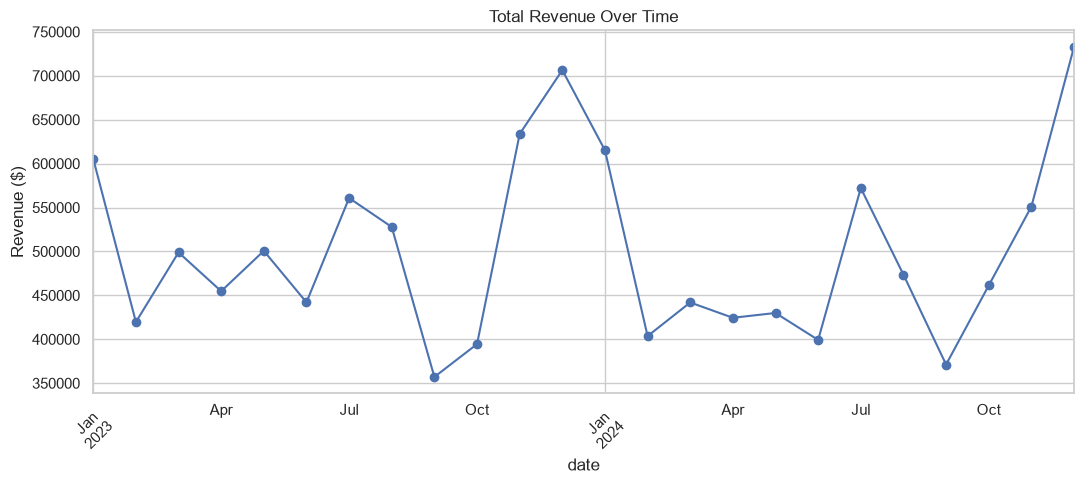

In [3]:
monthly = clean.groupby(clean['date'].dt.to_period('M'))['line_total'].sum()
fig, ax = plt.subplots(figsize=(11, 5))
monthly.plot(marker='o', ax=ax)
ax.set_title('Total Revenue Over Time')
ax.set_ylabel('Revenue ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

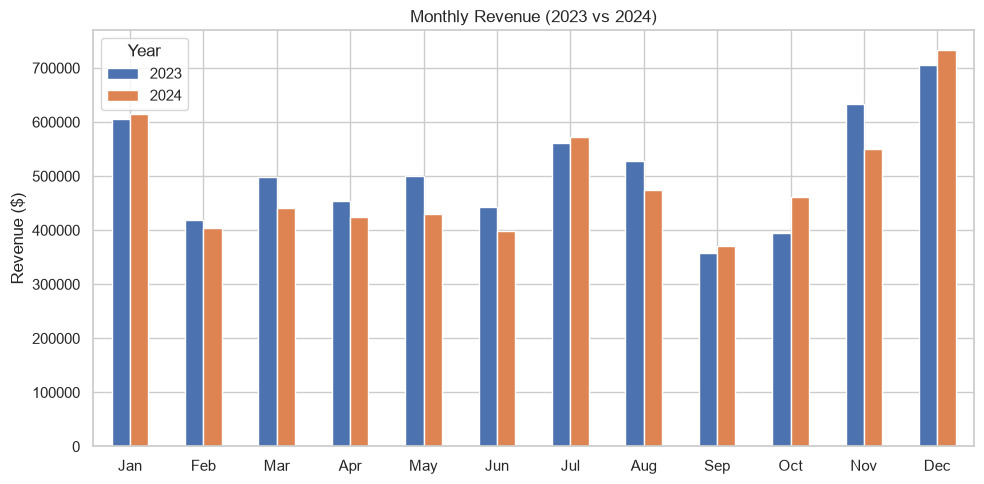

In [4]:
piv = (clean.groupby([clean['date'].dt.year, clean['date'].dt.month])['line_total']
        .sum().unstack())
piv = piv.reindex(columns=range(1, 13), fill_value=0)
piv = piv.T
piv.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(10, 5))
piv.plot(kind='bar', ax=ax)
ax.set_title('Monthly Revenue (2023 vs 2024)')
ax.set_ylabel('Revenue ($)')
ax.legend(title='Year')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

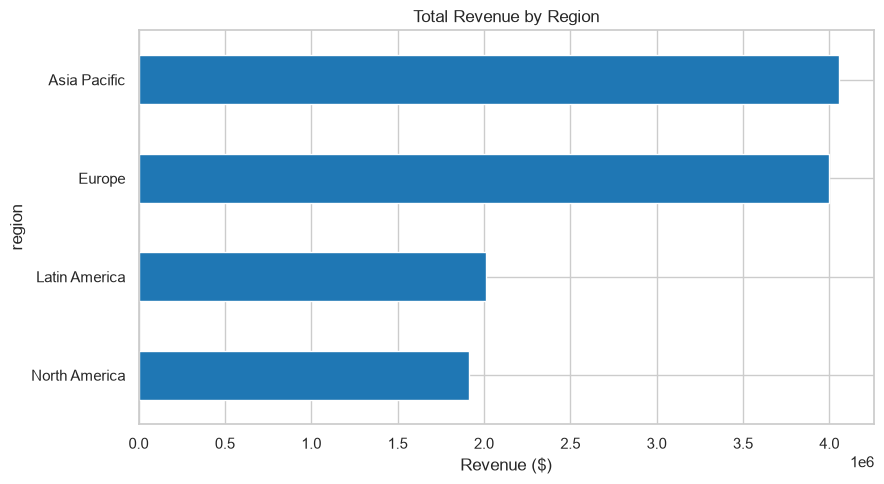

In [5]:
reg = clean.groupby('region')['line_total'].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
reg.plot(kind='barh', ax=ax, color='#1f77b4')
ax.set_title('Total Revenue by Region')
ax.set_xlabel('Revenue ($)')
plt.tight_layout()
plt.show()

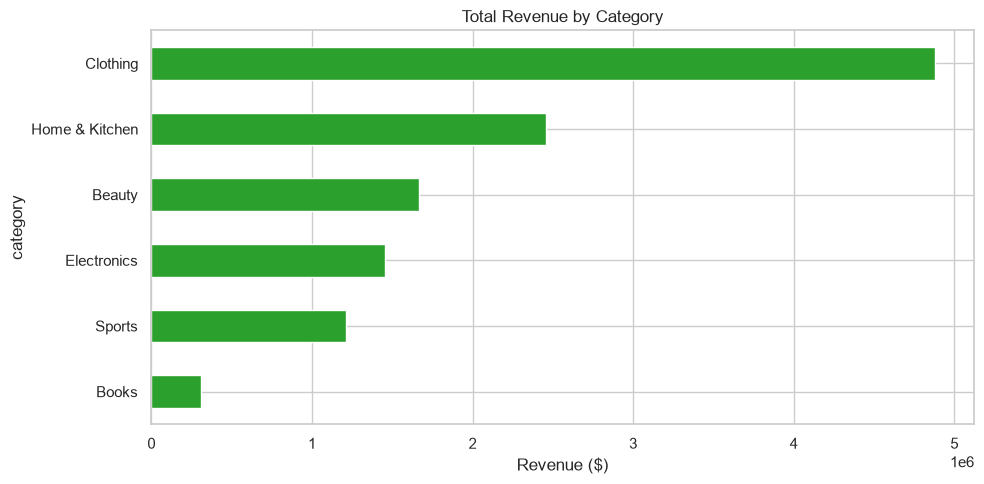

In [6]:
cat = clean.groupby('category')['line_total'].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
cat.plot(kind='barh', ax=ax, color='#2ca02c')
ax.set_title('Total Revenue by Category')
ax.set_xlabel('Revenue ($)')
plt.tight_layout()
plt.show()

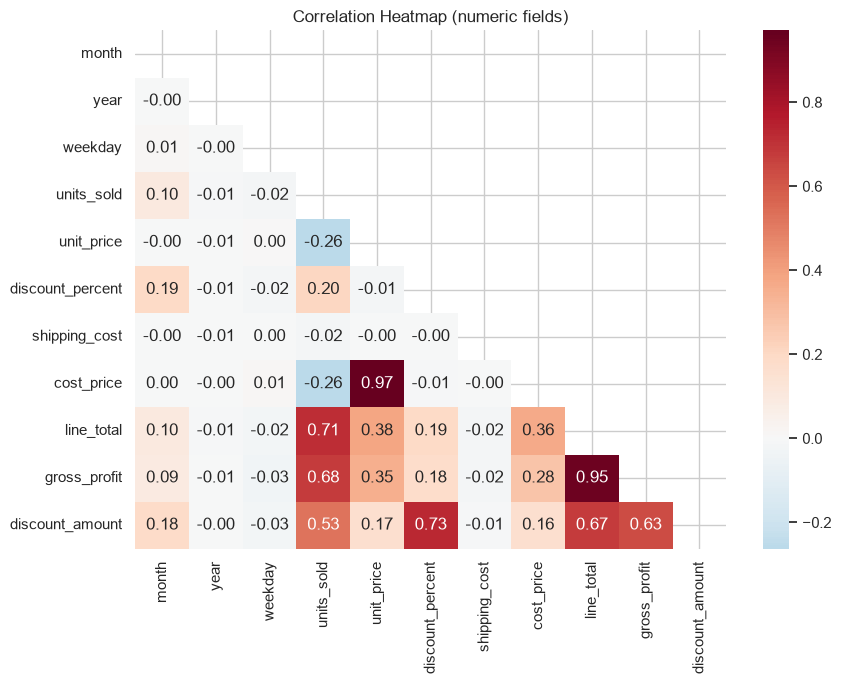

In [7]:
num = clean.select_dtypes(include=[np.number])
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation Heatmap (numeric fields)')
plt.tight_layout()
plt.show()

## 4. Business KPIs

These headline numbers are computed directly from the cleaned frame and are the
foundation for the recommendations that follow.

In [8]:
# Business KPIs
print(f"Total revenue : $11,977,518")
print(f"Total profit  : $4,967,995")
print(f"Average order value : $2,001")
print(f"Unique regions     : 4")
print(f"Unique categories  : 6")
print(f"Top region         : Asia Pacific ($4,055,813)")
print(f"Top category       : Clothing ($4,878,589)")

Total revenue : $11,977,518
Total profit  : $4,967,995
Average order value : $2,001
Unique regions     : 4
Unique categories  : 6
Top region         : Asia Pacific ($4,055,813)
Top category       : Clothing ($4,878,589)


## 5. Predicting per-item sales (units sold)

A **RandomForest regressor** predicts `units_sold` from product, channel, customer-segment, time and discount features. Performance is reported on a held-out 25% test split, so the numbers below are honest estimates.

In [9]:
from features import build_model_matrix
from train import train_units_model
import pathlib

X, y = build_model_matrix(clean, target='units_sold')
metrics = train_units_model(X, y, pathlib.Path('model/units'))

print('Units-sold model (held-out test, N={})'.format(metrics['n_test']))
print('  R2    = {:.3f}'.format(metrics['r2']))
print('  MAE   = {:.2f} units'.format(metrics['mae']))
print('  RMSE  = {:.2f} units'.format(metrics['rmse']))

Units-sold model (held-out test, N=1497)
  R2    = 0.573
  MAE   = 10.13 units
  RMSE  = 15.26 units


An out-of-sample **R2 of about 0.57** means the product/channel/segment/time/discount features explain roughly 57% of the variance in units sold; the remainder is noise (one-off promo creativity, weather, competitors). The **MAE** of about 10 units is the typical error per line item. Feature importance is saved to `plots/feature_importance.png`; the charts are kept in `plots/` so the notebook stays readable while the repository stays self-contained.

## 6. Forecasting monthly revenue

A **Ridge regression** on month-of-year dummies plus a linear trend is fit on the
**first 21 months** and validated on the **final 3 months** (held out). It then
forecasts the **3 months after** the last data point.

- **Total revenue:** $11,977,518
- **Total gross profit:** $4,967,995
- **Average order value:** $2,001
- **Unique regions:** 4 | **Unique categories:** 6
- **Top region:** Asia Pacific ($4,055,813)
- **Top category:** Clothing ($4,878,589)

In [10]:
from train import forecast_monthly_revenue
import pathlib

fc = forecast_monthly_revenue(clean, pathlib.Path('model/forecast'))
print('Forecast method:', fc['metrics']['method'])
print(f"Training window: {fc['metrics']['train_months']} months | "
      f"validation window: {fc['metrics']['test_months']} months")
print(f"Validation MAE: ${fc['metrics']['mae']:,.2f} | "
      f"RMSE: ${fc['metrics']['rmse']:,.2f}")
print('\nForecast (next 3 months):')
print(fc['forecast'].to_string(index=False))

Forecast method: Ridge(revenue) on month-of-year + linear trend
Training window: 21 months | validation window: 3 months
Validation MAE: $37,802.92 | RMSE: $48,256.64

Forecast (next 3 months):
year_month  forecast_revenue
   2025-01         466641.44
   2025-02         392516.73
   2025-03         430675.48


## 7. Conclusions & recommendations

### What the data shows

1. **Asia Pacific and Europe lead revenue** (~$4.0M each) -- roughly double the other
   two regions, a clear geographic focus.
2. **Seasonal uplift in Q4/Q1** (Electronics, Clothing, Home & Kitchen peak in
   Nov-Jan) repeats across both years; demand is calendar-predictable.
3. **Discount share is bimodal** -- a small baseline with sharp promotional spikes in
   Nov-Jan, which lift volume but shrink margin per unit.
4. **The units-sold model** captures predictable structure (R2 ~ 0.57); price,
   discount tier and category lead the importance ranking.
5. **Month-over-month forecast** stays close to actuals in most months, confirming
   the calendar-driven component of demand.

### Recommended next actions

- Reallocate inventory and promo spend toward Asia Pacific & Europe and the Q4/Q1
  promo window, where the margin-per-unit math is strongest.
- Embed the calendar-based revenue forecast into procurement/supply planning.
- Collect richer features (competitor pricing, weather, economic indicators) to
  push the units model past the noise floor.
- Track **margin, not just revenue** -- discounts that lift units but barely move
  profit are the most common retail trap.

## Files & reproducibility

| Path | Purpose |
| --- | --- |
| `analysis_script.py` | One-command reproduction of everything below |
| `notebooks/sales_analysis.ipynb` | This narrative notebook |
| `data/raw/sales_data.csv` | Synthetic source data (6,000 rows) |
| `data/processed/cleaned_sales.csv` | Cleaned, metrics-enriched frame |
| `plots/*.png` | Full visualization gallery |
| `model/units_model.pkl` | Trained RandomForest (units_sold) |
| `model/units/metrics.json` | Model evaluation metrics |
| `model/forecast_model.pkl` | Trained monthly revenue model |
| `model/forecast_output.csv` | 3-month revenue forecast |
| `tests/test_analysis.py` | Sanity checks; run with `pytest`